# Image processing with scikit:

Downsizing, rescaling, resizing:

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import io
from skimage.transform import rescale, resize, downscale_local_mean #reshape

## 1. Down-sizing images

See documentation here:
https://scikit-image.org/docs/stable/auto_examples/transform/plot_rescale.html

## Rescaling images

- The **rescale()** operation resizes an image by a given scaling factor.


- **rescale()** uses interpolation.


- The scaling factor can either be a single floating point value, or multiple values - one along each axis.


### 1. Let's generate matrices with numpy:

In [3]:
a_2d = np.arange(40).reshape(8, 5)

print(a_2d)
print(a_2d.shape)

[[ 0  1  2  3  4]
 [ 5  6  7  8  9]
 [10 11 12 13 14]
 [15 16 17 18 19]
 [20 21 22 23 24]
 [25 26 27 28 29]
 [30 31 32 33 34]
 [35 36 37 38 39]]
(8, 5)


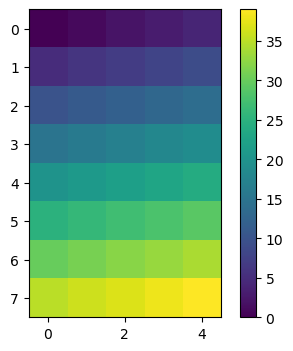

In [4]:
# Plotting
plt.figure(figsize = (5,4))

plt.imshow(a_2d)

plt.colorbar()

plt.show()

#### 2. Rescale image:

In [5]:
# New rescaled image
a_2d_rescaled = rescale(a_2d, scale = 4)

print(a_2d.shape, a_2d_rescaled.shape)

(8, 5) (32, 20)


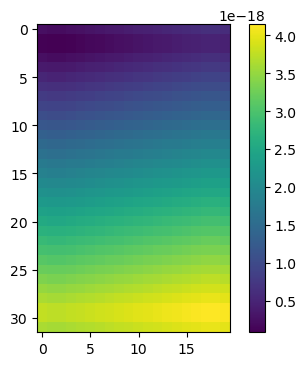

In [6]:
# Plotting
plt.figure(figsize = (5,4))

plt.imshow(a_2d_rescaled)
plt.colorbar()

plt.show()

In [9]:
# Print values:

#print(a_2d)
#print(a_2d_rescaled)

In [10]:
# New rescaled image
a_2d_rescaled2 = rescale(a_2d, scale = 4, preserve_range = True)

print(a_2d.shape, a_2d_rescaled.shape, a_2d_rescaled2.shape)

(8, 5) (32, 20) (32, 20)


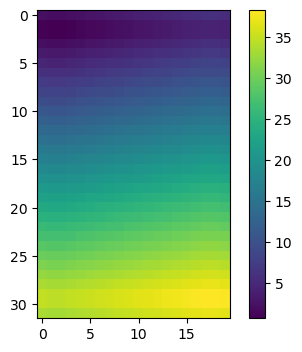

In [11]:
# Plotting
plt.figure(figsize = (5,4))

plt.imshow(a_2d_rescaled2)
plt.colorbar()

plt.show()

In [15]:
# Print values:

#print(a_2d)
#print(a_2d_rescaled)
#print(a_2d_rescaled2)

## Resizing images

- The **resize()** operation does the same as rescaling, but allows users to specify an output image shape instead of a scaling factor.


- **resize()** also uses interpolation.


- Note that when down-sampling an image, **resize** and **rescale** should perform Gaussian smoothing to avoid aliasing artifacts. See the anti_aliasing and anti_aliasing_sigma arguments to these functions.

In [16]:
# Resizing A

a_2d_resized = resize(a_2d, (40,60), preserve_range = True)

print(a_2d.shape, a_2d_resized.shape)

(8, 5) (40, 60)


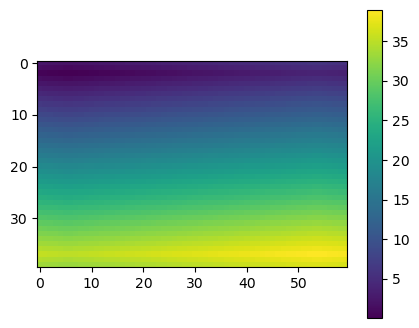

In [17]:
# Plotting
plt.figure(figsize = (5,4))

plt.imshow(a_2d_resized)
plt.colorbar()

plt.show()

## Downscaling images

- The **downscale_local_mean()** function serves the purpose of down-sampling an n-dimensional image by integer factors using the local mean on the elements of each block of the size factors given as a parameter to the function.



- This function calculates the local mean of elements in each block of size factors in the input image.

In [20]:
# Resizing A

a_2d_downscaled = downscale_local_mean(a_2d, (2,2))

print(a_2d.shape, a_2d_downscaled.shape)

(8, 5) (4, 3)


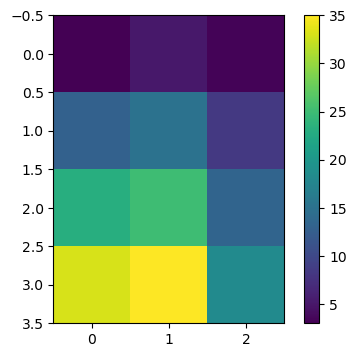

In [21]:
# Plotting
plt.figure(figsize = (5,4))

plt.imshow(a_2d_downscaled)
plt.colorbar()

plt.show()

### Example: Satellite image

#### You can download your own image from:
https://www.meteoblue.com/en/country/weather/satellite/ecuador_ecuador_3658394

#### Or, use this one:
https://github.com/wbandabarragan/physics-teaching-data/blob/main/2D-data/Satellite-No-Radar_20220621T20220621_1115.jpeg


In [23]:
# Open the image:

image_sat = io.imread("./Satellite-No-Radar_20261014T0900000500.jpeg")

print(type(image_sat))
print(image_sat.shape)
print(np.min(image_sat[:,:,0]), np.max(image_sat[:,:,0]))
print(np.min(image_sat[:,:,1]), np.max(image_sat[:,:,1]))
print(np.min(image_sat[:,:,2]), np.max(image_sat[:,:,2]))

<class 'numpy.ndarray'>
(776, 1034, 3)
0 255
0 255
0 255


In [24]:
# Open the image:

image_sat_gray = io.imread("./Satellite-No-Radar_20261014T0900000500.jpeg", as_gray = True)

print(type(image_sat_gray))
print(image_sat_gray.shape)
print(np.min(image_sat_gray), np.max(image_sat_gray))

<class 'numpy.ndarray'>
(776, 1034)
0.0 1.0


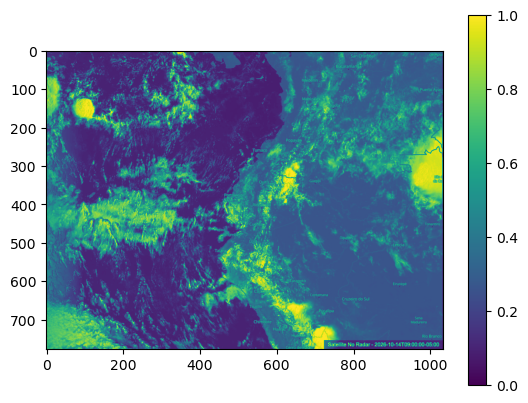

In [25]:
# Plotting

fig, ax = plt.subplots()

z = ax.imshow(image_sat_gray, cmap = "viridis")

plt.colorbar(z)

plt.show()

#### Rescaling the image

In [26]:
rescaled_sat_gray = rescale(image_sat_gray, scale = 1.5, preserve_range = True, anti_aliasing = True)

print(rescaled_sat_gray.shape)

(1164, 1551)


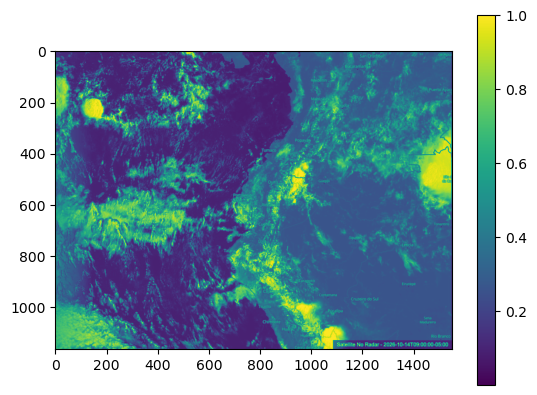

In [27]:
# Plotting

fig, ax = plt.subplots()

z = ax.imshow(rescaled_sat_gray, cmap = "viridis")

plt.colorbar(z)

plt.show()

#### Same exercise: Resizing the satellite image

In [28]:
resized_sat_gray = resize(image_sat_gray, (250, 350), preserve_range = True, anti_aliasing = True)

print(resized_sat_gray.shape)

(250, 350)


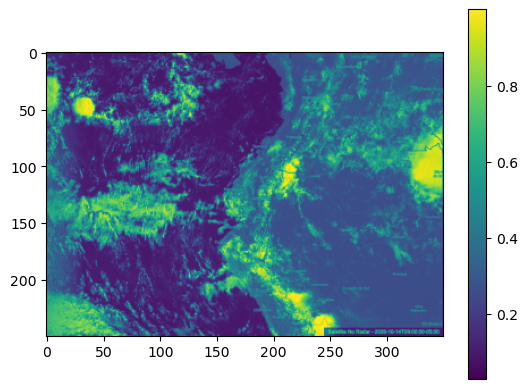

In [29]:
# Plotting

fig, ax = plt.subplots()

z = ax.imshow(resized_sat_gray, cmap = "viridis")

plt.colorbar(z)

plt.show()

#### Same exercise: Downscaling the satellite image

In [30]:
downscaled_sat_gray = downscale_local_mean(image_sat_gray, (2, 2))

print(image_sat_gray.shape, downscaled_sat_gray.shape)

(776, 1034) (388, 517)


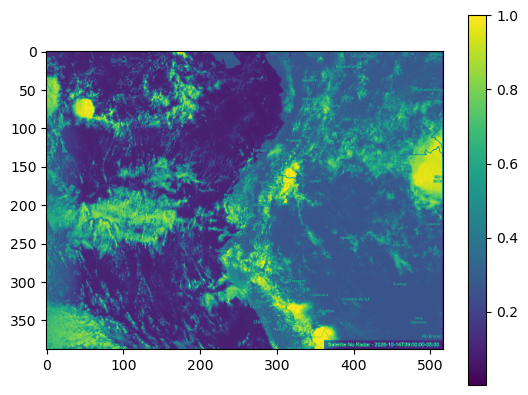

In [31]:
# Plotting

fig, ax = plt.subplots()

z = ax.imshow(downscaled_sat_gray, cmap = "viridis")

plt.colorbar(z)

plt.show()

## Gaussian smoothing with scipy:

In [32]:
from scipy.ndimage import gaussian_filter

In [33]:
# Go back to our A matrix

print(a_2d)

print(a_2d.shape)

[[ 0  1  2  3  4]
 [ 5  6  7  8  9]
 [10 11 12 13 14]
 [15 16 17 18 19]
 [20 21 22 23 24]
 [25 26 27 28 29]
 [30 31 32 33 34]
 [35 36 37 38 39]]
(8, 5)


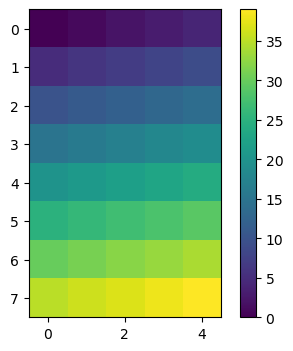

In [34]:
# Plotting
plt.figure(figsize = (5,4))

plt.imshow(a_2d)
plt.colorbar()

plt.show()

In [35]:
# Apply a Gaussian filter

a_2d_smoothed = gaussian_filter(a_2d, sigma = 1.)

print(a_2d_smoothed)

[[ 2  3  4  4  5]
 [ 5  6  7  7  8]
 [10 11 12 12 13]
 [15 16 17 17 18]
 [19 20 21 21 22]
 [24 25 26 26 27]
 [29 30 31 31 32]
 [32 33 34 34 35]]


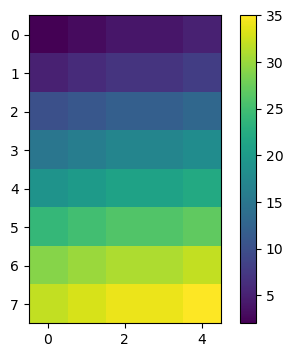

In [36]:
# Plotting
plt.figure(figsize = (5,4))

plt.imshow(a_2d_smoothed)
plt.colorbar()

plt.show()

#### Same exercise: Gaussian smoothing on the satellite image

In [37]:
smoothed_sat_gray = gaussian_filter(image_sat_gray, sigma = 1.)

print(image_sat_gray.shape, smoothed_sat_gray.shape)

(776, 1034) (776, 1034)


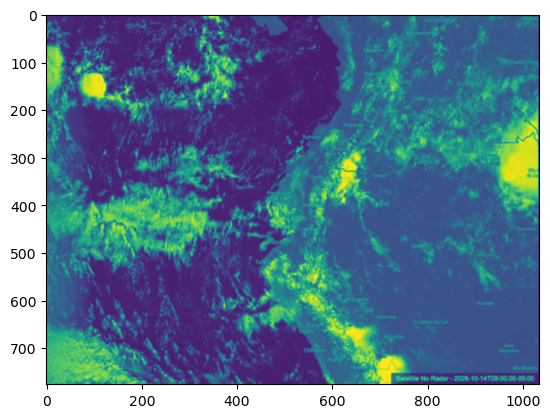

In [38]:
# Plotting

fig, ax = plt.subplots()

ax.imshow(smoothed_sat_gray , cmap = "viridis")

plt.show()

In [39]:
smoothed_sat_gray2 = gaussian_filter(image_sat_gray, sigma = 10.)

print(image_sat_gray.shape, smoothed_sat_gray2.shape)

(776, 1034) (776, 1034)


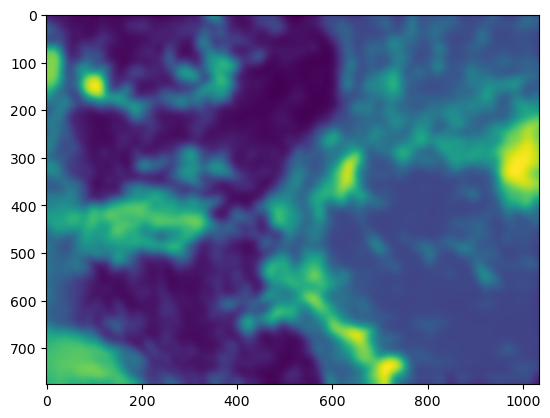

In [40]:
# Plotting

fig, ax = plt.subplots()

ax.imshow(smoothed_sat_gray2 , cmap = "viridis")

plt.show()

### Pixel Histograms:

In [41]:
# Flatten the arrays
image_1D = image_sat_gray.reshape((image_sat_gray.size,1))

smoothed_1D = smoothed_sat_gray.reshape((image_sat_gray.size,1))

smoothed_1D2 = smoothed_sat_gray2.reshape((smoothed_sat_gray2.size,1))

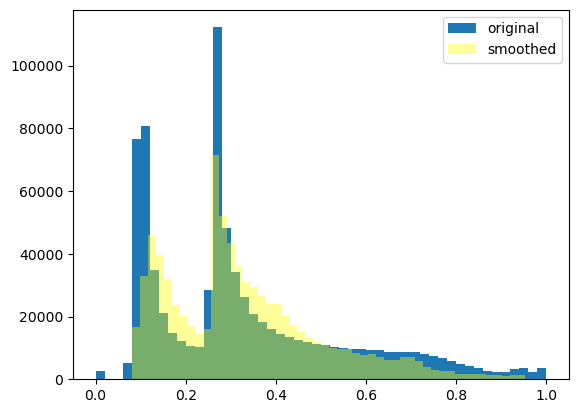

In [42]:
# Plotting the histograms

plt.figure()

plt.hist(image_1D, bins = 50, label = "original")
#plt.hist(smoothed_1D, bins = 50, label = "smoothed", alpha = 0.4, color ="magenta")

plt.hist(smoothed_1D2, bins = 50, label = "smoothed", alpha = 0.4, color ="yellow")

plt.legend()
plt.show()